## 1. Evaluation Metrics: Overview

In the previous chapter we trained a logistic regression model that predicts customer churn.  
Now we need to answer the question: how do we know if it's good?  
We first recap the code that gets us back to the trained model, and then we look at the metrics we will use to evaluate it.

### What is a Metric

A **metric** is **a function that compares the predictions with the actual values and outputs a single number that tells how good the predictions are**.

That is all a metric is: **predictions go in, the true values go in, and one number comes out**.  
**Different metrics look at different aspects of the predictions, and picking the right one for the problem is the topic of this whole chapter.**

### The dataset

We keep working with the telco churn dataset from the previous chapter.  
Each row is a customer of a telecom company, and the target is the `churn` column: 1 if the customer left, 0 if they stayed. The dataset comes from Kaggle.  
Dataset: https://www.kaggle.com/blastchar/telco-customer-churn

In [47]:
data = 'https://raw.githubusercontent.com/k-candidate/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv'
!wget -nc $data -O data-week-3.csv

File ‘data-week-3.csv’ already there; not retrieving.


### Recap: back to the trained model

The section is mostly a recap of the code from module 3. The metric discussion starts in the next section, and for that we need a model and its predictions.

First, we load the data and clean it: column names are lowercased, spaces are replaced with underscores, `totalcharges` is converted to numbers with `errors='coerce'` and the missing values are filled with 0, and the target is turned into 0/1:

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

In [5]:
from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_curve, auc, roc_auc_score

In [6]:
import random

In [8]:
df = pd.read_csv('data-week-3.csv')

df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0)

df.churn = (df.churn == 'yes').astype(int)

Then we split the data into train, validation and test: 60% for training, 20% for validation and 20% for test.  
We do it in two steps: first split off the test set, then split the rest. And we use `random_state=1` so the shuffle is reproducible:

In [9]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

del df_train['churn']
del df_val['churn']
del df_test['churn']

We keep 3 numerical features (`tenure`, `monthlycharges`, `totalcharges`) and 16 categorical ones, one-hot encode them with `DictVectorizer(sparse=False)`, and train a logistic regression model.

In [10]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]

In [11]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use 

At the end of the recap we get predictions on the validation set. `predict_proba` returns the churn probability for each customer, and we say the model predicts churn when this probability is at least 0.5:

In [13]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)
(y_val == churn_decision).mean()

np.float64(0.8034066713981547)

This gives us `0.8034066713981547`: the model agrees with the actual outcomes about 80% of the time.  
**Is 80% good? That is exactly what we cannot tell yet: a single agreement number is the simplest metric, accuracy**, and in the next lesson we start poking at it.

## 2. Accuracy and a dummy model

In this section we look at **accuracy, the simplest evaluation metric: the fraction of predictions the model got right**.  
We check whether 0.5 is the best decision threshold for our churn model, and then compare it against a dummy model that predicts nobody will churn.

### Accuracy

**Accuracy measures the fraction of correct predictions: the number of correct predictions divided by the total number of predictions.**

Our validation set has 1409 customers:

In [55]:
len(y_val)

1409

This gives `1409`. With the decision threshold at 0.5, the model made the right call for `1132` of them:

In [56]:
# The sum of Trues or ones (correct predictions)
(y_val == churn_decision).sum()

np.int64(1132)

In [57]:
(y_val == churn_decision).mean()

np.float64(0.8034066713981547)

In [58]:
1132 / 1409

0.8034066713981547

This gives `0.8034066713981547`. Indeed, 1132 / 1409 is 0.8034: about 80% of the predictions match the actual outcomes.

Scikit-learn has this computation built in as `accuracy_score`:

In [59]:
accuracy_score(y_val, y_pred >= 0.5)

0.8034066713981547

This gives the same `0.8034066713981547`.

### Checking different thresholds

The 0.5 threshold was a guess. Nothing forces us to use it: the model outputs a probability, and we can announce churn for any cutoff we like.  
Let's check all thresholds from 0 to 1 in steps of 0.05 and see which one gives the best accuracy:

In [14]:
thresholds = np.linspace(0, 1, 21)

scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred >= t)
    print('%.2f %.3f' % (t, score))
    scores.append(score)

0.00 0.274
0.05 0.513
0.10 0.608
0.15 0.661
0.20 0.703
0.25 0.734
0.30 0.758
0.35 0.765
0.40 0.782
0.45 0.791
0.50 0.803
0.55 0.801
0.60 0.796
0.65 0.789
0.70 0.766
0.75 0.742
0.80 0.729
0.85 0.726
0.90 0.726
0.95 0.726
1.00 0.726


Plotted, the accuracy rises quickly, peaks around 0.5, and then slowly declines before flattening out:

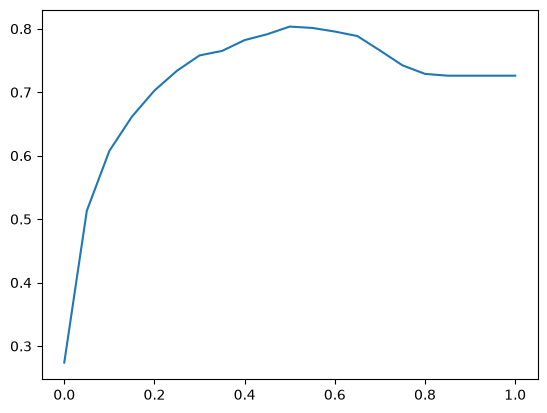

In [61]:
plt.plot(thresholds, scores);

**So for this problem the best decision cutoff is indeed 0.5, with 80% accuracy. That was a lucky guess. But it didn't have to be. On other problems the best threshold is often different from 0.5, and this simple loop is how you find it.**

### The dummy model

Here comes the uncomfortable check. What if we don't use a model at all, and simply predict that no customer will ever churn? That is the same as setting the threshold to 1.0: no prediction can reach it, so every customer is predicted as "no churn":

In [15]:
from collections import Counter

Counter(y_pred >= 1.0)

Counter({np.False_: 1409})

The output confirms it: every single prediction is `False`.

What accuracy does this dummy model get? The answer is the fraction of customers who did not churn:

In [63]:
1 - y_val.mean()

np.float64(0.7260468417317246)

This gives 0.7260468417317246: 73%.

**So a model that doesn't look at the data at all scores 73%, and our logistic regression scores 80%. The improvement over the dummy baseline is much smaller than "80% correct" made it sound.**

### Why accuracy fails here: class imbalance

**The reason is that the classes are unbalanced: only 27% of the customers in the validation set churned, and 73% stayed (73% is the accuracy of the "nobody churns" dummy model). This is called class imbalance: there are many more instances of one class than of the other.**

**With such an imbalance, a model can get a high accuracy by always predicting the majority class, while being completely useless for the minority class, which is exactly the class we care about: we want to find the customers who are about to leave.**

So for this problem, accuracy alone cannot tell us how good the model is. We need metrics that look at the errors in more detail. That is what the confusion table in the next section is for.

## 3. Confustion Table

Accuracy collapses all predictions into a single number, so it cannot tell us which kinds of mistakes the model makes.  
In this section we look at the confusion table: a way of measuring the different types of errors and correct decisions a binary classifier can make, arranged in one table.

### Four Outcomes of a prediction

For churn prediction, each customer in the validation set falls into one of four categories, depending on what we predicted and what actually happened:

<div style="display: flex; justify-content: center;">
  <table style="border-collapse: collapse; border: none;">
    <tr>
      <th style="text-align:left; font-weight: bold; padding: 12px; border: 1px solid black; background-color: #f1f3f4;">Prediction</th>
      <th style="text-align:left; font-weight: bold; padding: 12px; border: 1px solid black; background-color: #f1f3f4;">Actual</th>
      <th style="text-align:left; font-weight: bold; padding: 12px; border: 1px solid black; background-color: #f1f3f4;">Name</th>
    </tr>
    <tr>
      <td style="text-align:left; padding: 12px; border: 1px solid black;">Customer will churn (positive)</td>
      <td style="text-align:left; padding: 12px; border: 1px solid black;">Churned</td>
      <td style="text-align:left; padding: 12px; border: 1px solid black;">True Positive (TP)</td>
    </tr>
    <tr>
      <td style="text-align:left; padding: 12px; border: 1px solid black;">Customer will churn (positive)</td>
      <td style="text-align:left; padding: 12px; border: 1px solid black;">Did not churn</td>
      <td style="text-align:left; padding: 12px; border: 1px solid black;">False Positive (FP)</td>
    </tr>
    <tr>
      <td style="text-align:left; padding: 12px; border: 1px solid black;">Customer will not churn (negative)</td>
      <td style="text-align:left; padding: 12px; border: 1px solid black;">Churned</td>
      <td style="text-align:left; padding: 12px; border: 1px solid black;">False Negative (FN)</td>
    </tr>
    <tr>
      <td style="text-align:left; padding: 12px; border: 1px solid black;">Customer will not churn (negative)</td>
      <td style="text-align:left; padding: 12px; border: 1px solid black;">Did not churn</td>
      <td style="text-align:left; padding: 12px; border: 1px solid black;">True Negative (TN)</td>
    </tr>
  </table>
</div>


Reading the names: "positive"/"negative" is what we predicted, "true"/"false" is whether that prediction was correct.  
A false positive is a customer we sent a promotional email to, but who was never going to leave.  
A false negative is a customer who left without us ever flagging them, often the more costly mistake.

<img src="https://github.com/k-candidate/machine-learning-zoomcamp/raw/main/04-evaluation/images/03-confusion-table-01-four-outcomes-crisp.jpg" alt="Outcomes of a prediction" style="max-width: 100%; height: auto; display: block; margin: 0 auto;">

### Computing the counts

To put every customer into one of the four cells, we compare the actual values with the predictions at threshold 0.5:

In [16]:
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

t = 0.5
predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

Each cell is the number of customers where the two conditions hold at the same time. The `&` operator is the element-wise logical AND:

In [17]:
tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()

fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

tp, tn, fp, fn, tp + tn + fp + fn

(np.int64(212), np.int64(920), np.int64(103), np.int64(174), np.int64(1409))

For our model this gives tp = 212, tn = 920, fp = 103 and fn = 174  
And indeed 212 + 920 + 103 + 174 = 1409, all customers accounted for.

<img src="https://github.com/k-candidate/machine-learning-zoomcamp/raw/main/04-evaluation/images/03-confusion-table-04-confusion-counts-crisp.jpg" alt="Outcomes of a prediction" style="max-width: 100%; height: auto; display: block; margin: 0 auto;">

### The table

Arranging the four numbers with predictions in columns and actual values in rows gives the confusion table:

In [18]:
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])
confusion_matrix

array([[920, 103],
       [174, 212]])

<div style="display: flex; justify-content: center;">
  <table style="border-collapse: collapse; border: none;">
    <tr>
      <th style="border: none; background: transparent;"></th>
      <th style="text-align:center; font-weight: bold; padding: 10px; border: 1px solid black; background-color: #f1f3f4;">Predicted negative</th>
      <th style="text-align:center; font-weight: bold; padding: 10px; border: 1px solid black; background-color: #f1f3f4;">Predicted positive</th>
    </tr>
    <tr>
      <th style="text-align:left; font-weight: bold; padding: 10px; border: 1px solid black; background-color: #f1f3f4;">Actual negative</th>
      <td style="text-align:center; padding: 10px; border: 1px solid black;">TN = 920</td>
      <td style="text-align:center; padding: 10px; border: 1px solid black;">FP = 103</td>
    </tr>
    <tr>
      <th style="text-align:left; font-weight: bold; padding: 10px; border: 1px solid black; background-color: #f1f3f4;">Actual positive</th>
      <td style="text-align:center; padding: 10px; border: 1px solid black;">FN = 174</td>
      <td style="text-align:center; padding: 10px; border: 1px solid black;">TP = 212</td>
    </tr>
  </table>
</div>



Dividing each cell by the total gives the counts into fractions of the whole validation set:

In [68]:
(confusion_matrix / confusion_matrix.sum()).round(2)

array([[0.65, 0.07],
       [0.12, 0.15]])

So 65% of all customers are true negatives, 7% false positives, 12% false negatives and 15% true positives.

**Accuracy** fits right back in: it **is the sum of the diagonal (the correct decisions TN and TP) divided by the total**. Here (920 + 212) / 1409 = 0.8034, the same 80% as before.  
What the table adds is the split of the remaining 20% into 7% of false positives and 12% of false negatives - two errors with very different business costs.

<div style="display: flex; justify-content: center;">
  <table style="border-collapse: collapse; border: none;">
    <tr>
      <th colspan="2" rowspan="2" style="border: none; background: transparent;"></th>
      <th colspan="2" style="text-align:center; border: 1px solid black;">PREDICTION</th>
    </tr>
    <tr>
      <th style="text-align:center; border: 1px solid black;">-</th>
      <th style="text-align:center; border: 1px solid black;">+</th>
    </tr>
    <tr>
      <th rowspan="2" style="vertical-align:middle; text-align:center; padding: 10px; border: 1px solid black;">ACTUAL</th>
      <th style="text-align:center; padding: 10px; border: 1px solid black;">-</th>
      <td style="text-align:center; padding: 10px; border: 1px solid black;">TN</td>
      <td style="text-align:center; padding: 10px; border: 1px solid black;">FP</td>
    </tr>
    <tr>
      <th style="text-align:center; padding: 10px; border: 1px solid black;">+</th>
      <td style="text-align:center; padding: 10px; border: 1px solid black;">FN</td>
      <td style="text-align:center; padding: 10px; border: 1px solid black;">TP</td>
    </tr>
  </table>
</div>


$$Accuracy = TN + TP$$


## 4. Precision and Recall

The confusion table showed us our model makes two very different kinds of mistakes.  
Precision and recall are the two metrics that look at each kind separately: they both focus on the positive class (the customers we want to catch) and they both see problems that accuracy hides.

### Precision

**Precision** tells us **the fraction of positive predictions that are correct**. It looks only at the customers we predicted to churn - the positive column of the confusion table (TP and FP):

$$\text{Precision} = P = \frac{\text{TP}}{\text{TP} + \text{FP}}$$

In [19]:
p = tp / (tp + fp)
p

np.float64(0.6730158730158731)

Precision of about 67%.

In the terms of the churn problem: we send a retention email to everyone predicted to churn.  That is 212 + 103 = 315 people, but only 212 of them (the true positives) were actually going to leave.  
The other 101 (about a third of all emails) go to customers who were never at risk, and the discount we send them is wasted.

### Recall

**Recall** measures **the fraction of actual positive instances that we identified correctly**.  
It looks at the customers who really churned: the positive row of the confusion table (TP and FN).

$$\text{Recall} = R = \frac{\text{TP}}{\text{TP} + \text{FN}}$$

In [20]:
r = tp / (tp + fn)
r

np.float64(0.5492227979274611)

Recall of about 54%.

Again in the terms of the problem: 212 + 174 = 386 customers actually churned, but our model flagged only 212 of them. For the remaining 174 (about 46% of all churners) we did nothing: no email, no discount, and the customer left. This is the part accuracy never showed us.

### Why not just accuracy

Remember what accuracy said: 80% correct, only 4 points above the dummy model. Precision and recall explain where the model actually stands: of the customers we alert, two thirds are real (precision 67%), but we miss almost half of the customers who leave (recall 54%).

<div style="display: flex; justify-content: center;">
  <table style="border-collapse: collapse; border: none;">
    <tr>
      <th colspan="2" rowspan="2" style="border: none; background: transparent;"></th>
      <th colspan="2" style="text-align:center; height: 50px; border: 1px solid black;">PREDICTION</th>
    </tr>
    <tr>
      <th style="text-align:center; width: 140px; height: 40px; border: 1px solid black;">-</th>
      <th style="text-align:center; width: 140px; height: 40px; border: 1px solid black;">+</th>
    </tr>
    <tr>
      <th rowspan="2" style="vertical-align:middle; text-align:center; width: 100px; height: 100px; border: 1px solid black;">ACTUAL</th>
      <th style="text-align:center; width: 40px; border: 1px solid black;">-</th>
      <!-- TN: Cool Mint Green for True Predictions -->
      <td style="text-align:center; width: 140px; height: 50px; background-color: #e6f4ea; color: #137333; border: 1px solid black;">TN</td>
      <!-- FP: Soft Coral for Errors -->
      <td style="text-align:center; width: 140px; height: 50px; background-color: #fce8e6; color: #c5221f; border: 1px solid black;">FP</td>
    </tr>
    <tr>
      <th style="text-align:center; border: 1px solid black;">+</th>
      <!-- FN: Soft Coral for Errors -->
      <td style="text-align:center; height: 50px; background-color: #fce8e6; color: #c5221f; border: 1px solid black;">FN</td>
      <!-- TP: Cool Mint Green for True Predictions -->
      <td style="text-align:center; height: 50px; background-color: #e6f4ea; color: #137333; border: 1px solid black;">TP</td>
      <!-- Recall: Soft Lavender for downstream metrics -->
      <td style="text-align:center; width: 140px; height: 50px; font-weight: bold; font-size: 0.9em; padding: 5px; background-color: #f1f3f4; color: #3c4043; border: 1px solid black;">Recall:<br>TP / (TP + FN)</td>
    </tr>
    <tr>
      <td colspan="3" style="border: none; background: transparent;"></td>
      <!-- Precision: Soft Lavender for downstream metrics -->
      <td style="text-align:center; height: 50px; font-weight: bold; font-size: 0.9em; padding: 5px; background-color: #f1f3f4; color: #3c4043; border: 1px solid black;">Precision:<br>TP / (TP + FP)</td>
      <!-- Accuracy: Anchors the bottom-right corner -->
      <td style="text-align:center; height: 50px; font-weight: bold; font-size: 0.9em; padding: 5px; background-color: #e8f0fe; color: #1a73e8; border: 1px solid black;">Accuracy:<br>(TN + TP) / All</td>
    </tr>
  </table>
</div>

These numbers reflect the errors of our model that accuracy did not notice because of class imbalance: churners are only 27% of the data, so the 12% of false negatives barely move the accuracy number, yet they are half of all the customers we care about. When the classes are imbalanced (churn, fraud, medical diagnosis) precision and recall are the metrics to look at.

## 5. ROC Curves

**Precision and recall look at the model at one fixed threshold**.  
**A ROC curve looks at all possible thresholds at once, which makes it a way to evaluate the performance of a binary classifier over its whole range of operating points.**  
**ROC** stands for **Receiver Operating Characteristic**: the idea comes from the Second World War, where it was used to evaluate the strength of radio detectors.

### TPR and FPR

**The ROC curve is built from two rates derived from the confusion table.**

The **true positive rate (TPR)** is the **fraction of actual positives we identified correctly** (it is the **same thing as recall**): TP divided by all positive observations (TP and FN, the second row of the table). **This is the metric we want to maximize**.

$$\text{TPR} = \text{Recall} = R = \frac{\text{TP}}{\text{TP} + \text{FN}}$$

In [21]:
tpr = tp / (tp + fn)
tpr

np.float64(0.5492227979274611)

The **false positive rate (FPR)** is **the fraction of actual negatives we got wrong**: FP divided by all negative observations (FP and TN, the first row of the table). **This is the metric we want to minimize**.

$$\text{FPR} = \frac{\text{FP}}{\text{FP} + \text{TN}}$$

In [22]:
fpr = fp / (fp + tn)
fpr

np.float64(0.10068426197458455)

We bother 10% of the customers who were never going to churn.

<div style="display: flex; justify-content: center;">
  <table style="border-collapse: collapse; border: none;">
    <tr>
      <th colspan="2" rowspan="2" style="border: none; background: transparent;"></th>
      <th colspan="2" style="text-align:center; height: 50px; border: 1px solid black;">PREDICTION</th>
    </tr>
    <tr>
      <th style="text-align:center; width: 160px; height: 40px; border: 1px solid black;">-</th>
      <th style="text-align:center; width: 160px; height: 40px; border: 1px solid black;">+</th>
    </tr>
    <tr>
      <th rowspan="2" style="vertical-align:middle; text-align:center; width: 100px; height: 130px; border: 1px solid black;">ACTUAL</th>
      <th style="text-align:center; width: 40px; border: 1px solid black;">-</th>
      <!-- TN: Cool Mint Green for True Predictions -->
      <td style="text-align:center; width: 160px; height: 65px; background-color: #e6f4ea; color: #137333; border: 1px solid black;">TN</td>
      <!-- FP: Soft Coral for Errors -->
      <td style="text-align:center; width: 160px; height: 65px; background-color: #fce8e6; color: #c5221f; border: 1px solid black;">FP</td>
      <!-- FPR: Soft Melon/Orange representing an Error-based Metric -->
      <td style="text-align:center; width: 160px; height: 65px; font-weight: bold; font-size: 0.85em; padding: 5px; background-color: #feefe3; color: #b06000; border: 1px solid black;">
        FPR:<br>False Positive Rate<br>FPR = FP / (FP + TN)
      </td>
    </tr>
    <tr>
      <th style="text-align:center; border: 1px solid black;">+</th>
      <!-- FN: Soft Coral for Errors -->
      <td style="text-align:center; height: 65px; background-color: #fce8e6; color: #c5221f; border: 1px solid black;">FN</td>
      <!-- TP: Cool Mint Green for True Predictions -->
      <td style="text-align:center; height: 65px; background-color: #e6f4ea; color: #137333; border: 1px solid black;">TP</td>
      <!-- Recall / TPR: Soft Lavender for standard positive class metrics -->
      <td style="text-align:center; width: 160px; height: 65px; font-weight: bold; font-size: 0.85em; padding: 5px; background-color: #f1f3f4; color: #3c4043; border: 1px solid black;">
        Recall:<br>True Positive Rate<br>TPR = R = TP / (TP + FN)
      </td>
    </tr>
    <tr>
      <td colspan="3" style="border: none; background: transparent;"></td>
      <!-- Precision: Updated layout to match P = TP / (TP + FP) -->
      <td style="text-align:center; height: 65px; font-weight: bold; font-size: 0.85em; padding: 5px; background-color: #f1f3f4; color: #3c4043; border: 1px solid black;">
        Precision:<br>P = TP / (TP + FP)
      </td>
      <!-- Accuracy: Ice Blue Grand Total -->
      <td style="text-align:center; height: 65px; font-weight: bold; font-size: 0.85em; padding: 5px; background-color: #e8f0fe; color: #1a73e8; border: 1px solid black;">
        Accuracy:<br>(TN + TP) / All
      </td>
    </tr>
  </table>
</div>

### TPR and FPR at all thresholds

These two numbers (TPR and FPR) describe the model at one threshold.  
Now let's compute them for many thresholds. We loop over 101 thresholds from 0 to 1 and record tp, fp, fn and tn for each:

In [23]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    scores.append((t, tp, fp, fn, tn))

In [24]:
columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

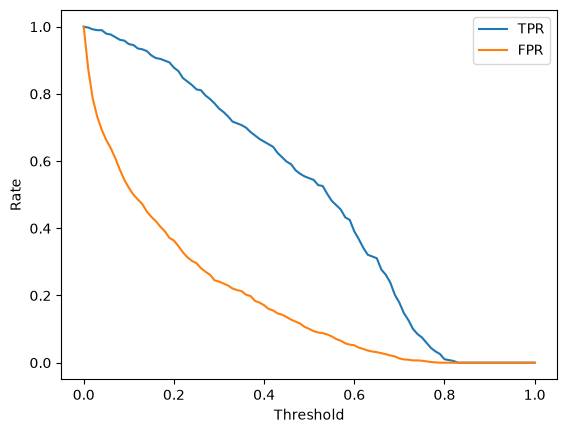

In [25]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR')
plt.xlabel('Threshold')
plt.ylabel('Rate')
plt.legend();

Plotting both rates (TPR and FPR) against the threshold shows how the trade-off shifts: as the threshold grows, we flag fewer customers, so both the true positive rate and the false positive rate fall.

### The random model

**To read the curve we made we need points of reference.**  
**The first reference: a model that outputs random scores**. We generate **a uniform random score for every customer**.

In [26]:
np.random.seed(1)
# We create an array y_rand with the size of y_val filled with random numbers in the range 0-1 drawn from a uniform distribution
y_rand = np.random.uniform(0, 1, size=len(y_val))
y_rand

array([4.17022005e-01, 7.20324493e-01, 1.14374817e-04, ...,
       7.73916250e-01, 3.34276405e-01, 8.89982208e-02], shape=(1409,))

Note:  
`np.random.uniform` belongs to the legacy random generation framework.  
`np.random.default_rng().uniform` is is the modern, recommended framework.

In [81]:
((y_rand >= 0.5) == y_val).mean()

np.float64(0.5017743080198722)

Its accuracy at threshold 0.5 is `0.5017743080198722`, which is basically 50%, a coin flip, as expected (random scores, with uniform distribution).  
Computing the TPR/FPR table for these random scores (with the same loop, wrapped in a reusable function `tpr_fpr_dataframe`) and plotting gives two almost straight lines going down together:

In [27]:
def tpr_fpr_dataframe(y_val, y_pred):
    scores = []

    thresholds = np.linspace(0, 1, 101)

    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)

        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()

        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()

        scores.append((t, tp, fp, fn, tn))

    columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
    df_scores = pd.DataFrame(scores, columns=columns)

    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)
    
    return df_scores

In [28]:
df_rand = tpr_fpr_dataframe(y_val, y_rand)

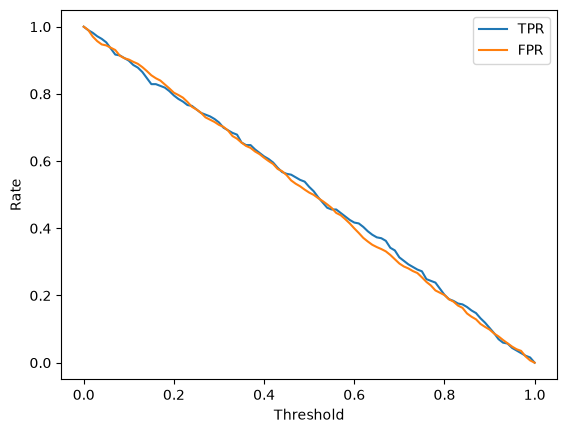

In [85]:
plt.plot(df_rand.threshold, df_rand['tpr'], label='TPR')
plt.plot(df_rand.threshold, df_rand['fpr'], label='FPR')
plt.xlabel('Threshold')
plt.ylabel('Rate')
plt.legend();

**For the random model, at any threshold the fraction of positives we catch is the same as the fraction of negatives we bother. It cannot tell the two groups apart.**

### The ideal model

**The second reference: an ideal model that ranks all customers perfectly** (every churner gets a higher score than every non-churner).  
**We build it by hand**: sort the customers so all 1023 negatives come first, then all 386 positives, and give them scores evenly spread from 0 to 1

In [29]:
num_neg = (y_val == 0).sum()
num_pos = (y_val == 1).sum()
num_neg, num_pos

(np.int64(1023), np.int64(386))

In [30]:
# create an array of num_neg zeros followed by num_pos ones
y_ideal = np.repeat([0, 1], [num_neg, num_pos])
y_ideal

array([0, 0, 0, ..., 1, 1, 1], shape=(1409,))

In [31]:
# create an array of evenly spaced probabilities from 0 to 1 to simulate a perfect model's prediction scores for each sample in the validation set.
y_ideal_pred = np.linspace(0, 1, len(y_val))
y_ideal_pred

array([0.00000000e+00, 7.10227273e-04, 1.42045455e-03, ...,
       9.98579545e-01, 9.99289773e-01, 1.00000000e+00], shape=(1409,))

array([0.72585227, 0.7265625 , 0.72727273])

array([0, 1, 1])

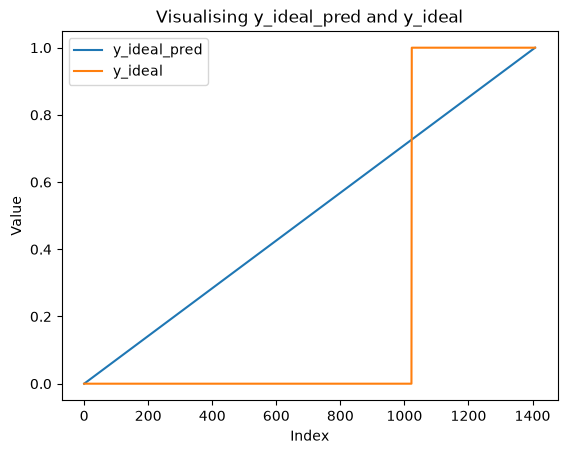

In [106]:
# This is just for me to understand.
plt.plot(y_ideal_pred, label='y_ideal_pred')
plt.plot(y_ideal, label='y_ideal')
plt.title("Visualising y_ideal_pred and y_ideal")
plt.xlabel("Index")
plt.ylabel("Value")
plt.legend();
# So basically, the point where they cross, x==1023, y==0.726. We can verify it with these 2 lines:
display(y_ideal_pred[1022:1025])
display(y_ideal[1022:1025])
# So if we put the threshold for predicting the churn right at the point, we would perfectly make every prediction, artificially of course.

In [92]:
1 - y_val.mean()

np.float64(0.7260468417317246)

Where should we put the threshold? At the fraction of negatives, 0.726, the ideal score that separates the two groups:

In [93]:
accuracy_score(y_ideal, y_ideal_pred >= 0.726)

1.0

This gives 1.0, perfect predictions, as an ideal model should.  
Its TPR and FPR vs threshold:

In [32]:
df_ideal = tpr_fpr_dataframe(y_ideal, y_ideal_pred)
df_ideal[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,386,882,0,141,1.000000,0.862170
20,0.2,386,741,0,282,1.000000,0.724340
30,0.3,386,600,0,423,1.000000,0.586510
40,0.4,386,459,0,564,1.000000,0.448680
50,0.5,386,319,0,704,1.000000,0.311828
60,0.6,386,178,0,845,1.000000,0.173998
70,0.7,386,37,0,986,1.000000,0.036168
80,0.8,282,0,104,1023,0.730570,0.000000
90,0.9,141,0,245,1023,0.365285,0.000000


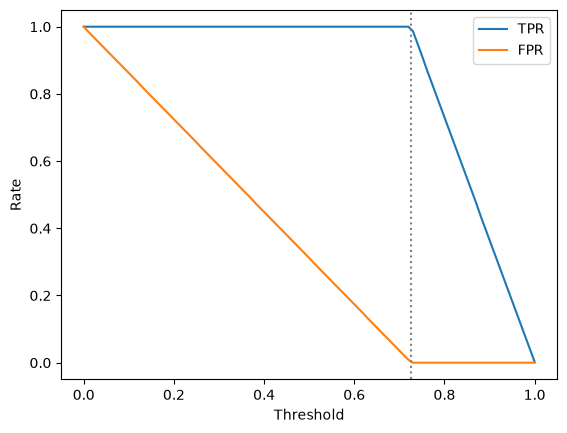

In [108]:
plt.plot(df_ideal.threshold, df_ideal['tpr'], label='TPR')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label='FPR')
plt.axvline(x=0.726, color='gray', linestyle=':')
plt.xlabel('Threshold')
plt.ylabel('Rate')
plt.legend();

The ideal TPR stays at 1.0 for every threshold below 0.726: it catches all churners while they all score higher than any non-churner, and only then drops. The ideal FPR falls to 0 at that same point.

### Putting everything together

Plotting our model together with the ideal one makes the comparison obvious: the black TPR curve of our model is clearly below the ideal, and the blue FPR curve below the ideal. The gap between them is the room our model still has to improve:

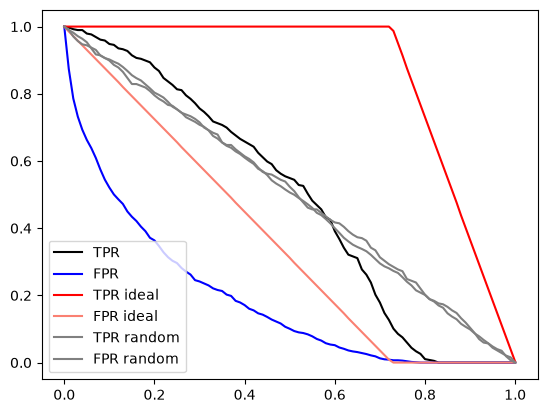

In [111]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR', color='black')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR', color='blue')

plt.plot(df_ideal.threshold, df_ideal['tpr'], label='TPR ideal', color='red')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label='FPR ideal', color='salmon')

plt.plot(df_rand.threshold, df_rand['tpr'], label='TPR random', color='gray')
plt.plot(df_rand.threshold, df_rand['fpr'], label='FPR random', color='gray')

plt.legend();

### The ROC Curve

**The ROC curve** itself **plots TPR against FPR**, not against the threshold.  
**Each point on the curve is the model operating at one threshold**: the bottom-left corner is a conservative model (flag almost nobody, bother almost nobody), the top-right corner flags everybody. We plot our model against the random one, which becomes the diagonal line from (0, 0) to (1, 1):

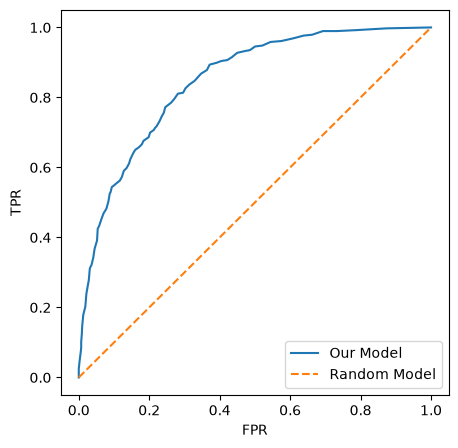

In [113]:
plt.figure(figsize=(5, 5))

# It is worth it to scroll a bit up to see how we got df_scores. Basically the scores for each threshold level.
plt.plot(df_scores.fpr, df_scores.tpr, label='Our Model')
plt.plot([0, 1], [0, 1], label='Random Model', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend();

**The lesson** to take away: **the closer the curve hugs the top-left corner (high TPR at a low FPR) the better the model.  
A curve sitting on the diagonal belongs to a random model.**

### ROC Curves with scikit-learn

**We don't have to compute the table by hand: `roc_curve` from scikit-learn does it in one call, returning the FPRs, the TPRs and the thresholds:**

In [33]:
# from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_val, y_pred)

The resulting curve is similar (a little bit more "jiggly" because it has more datapoints):

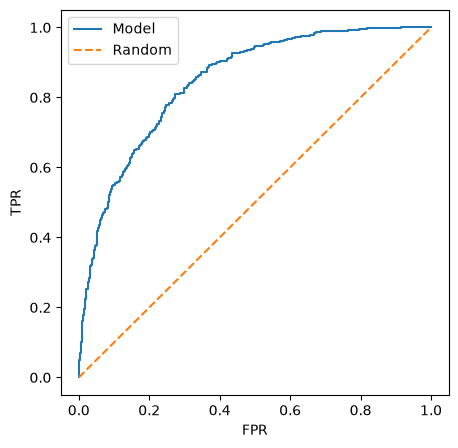

In [122]:
plt.figure(figsize=(5, 5))

plt.plot(fpr, tpr, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend();

What kind of information do we get from this curve? and how do we boil it down to a single number? That is the ROC AUC metric, the topic of the next section.

## 6. ROC AUC

A curve is a picture, not a number.  
In this lesson we compress the ROC curve into a single metric, the **area under the ROC curve** (ROC AUC or just AUC), and then look at a very useful interpretation of what that number actually means.

### Area Under the ROC Curve

The **ROC curve of a model:the TPR against the FPR at all thresholds**.  
The **AUC** of a ROC curve for a model is the **area under this ROC curve**.

The interpretation of the reference points follows straight from the shape of the curve:
- The **ideal model** covers the whole square above the diagonal, so its **AUC is 1**.
- The **random model** sits on the diagonal and covers only the triangle below it, so its **AUC is 0.5**.

A real model lands between 0.5 and 1: **the closer its curve is to the top-left corner, the larger the area under it**.  
**As a rule of thumb, an AUC around 0.8 is considered good, 0.9 is great, and 0.6 is poor.**

<img src="https://github.com/k-candidate/machine-learning-zoomcamp/raw/main/04-evaluation/images/06-auc-02-auc-values-imagegen.jpg" alt="ROC AUC" style="max-width: 100%; height: auto; display: block; margin: 0 auto;">

**Scikit-learn computes the area with `auc`, which works for any curve, not only ROC curves:**

In [34]:
# from sklearn.metrics import auc

auc(fpr, tpr)

# Btw, this is where those 2 numbers came from. We ran this earlier (above in this notebook)
# fpr, tpr, thresholds = roc_curve(y_val, y_pred)

0.8463120254863528

This gives `0.8463120254863528`.  
Feeding it the table we computed by hand in the previous lesson gives practically the same number: `0.8459194991870908`.  
And the ideal curve gives `0.9999430203759136`, almost exactly 1.

In [35]:
auc(df_scores.fpr, df_scores.tpr)

0.8459194991870908

In [36]:
auc(df_ideal.fpr, df_ideal.tpr)

0.9999430203759136

There is also a shortcut that computes the ROC curve and the area in one step:

In [37]:
# from sklearn.metrics import roc_auc_score

roc_auc_score(y_val, y_pred)

0.8463120254863528

This gives `0.8463120254863528`, the same value as with `auc(fpr, tpr)`.  
Our churn model has an **AUC of 0.84**: clearly **better than random, not far from ideal**.

### Interpreting AUC

**AUC has a second, probabilistic interpretation** that makes it very intuitive: **AUC is the probability that a randomly selected positive example has a greater score than a randomly selected negative example.**

In our case: **pick a random customer who churned and a random customer who stayed. How likely is it that our model gave the churner the higher risk score? That probability is exactly the AUC.**

We can check this by simulation. First we split the predictions into the scores of negatives and positives:

In [38]:
neg = y_pred[y_val == 0]
pos = y_pred[y_val == 1]
neg, pos

(array([0.0066238 , 0.20482253, 0.21781799, ..., 0.08290035, 0.29130676,
        0.15149644], shape=(1023,)),
 array([0.56375043, 0.59380571, 0.46602188, 0.73671762, 0.08257308,
        0.6949975 , 0.24905304, 0.68711688, 0.2184182 , 0.66247714,
        0.43815467, 0.35229513, 0.17171282, 0.59007584, 0.75027234,
        0.16044584, 0.4349552 , 0.28584394, 0.07537472, 0.22437698,
        0.65492017, 0.41971678, 0.66868184, 0.56910943, 0.53977218,
        0.44106616, 0.48371254, 0.33340156, 0.58462877, 0.34732773,
        0.61000641, 0.72954351, 0.72909964, 0.58951215, 0.68077991,
        0.76279634, 0.11035196, 0.20110648, 0.51463039, 0.56562619,
        0.46768427, 0.47944619, 0.7486788 , 0.38877417, 0.6875747 ,
        0.42481985, 0.74518847, 0.31571771, 0.53581632, 0.56932934,
        0.11258687, 0.5419867 , 0.78036282, 0.45200331, 0.68757235,
        0.7597699 , 0.01459588, 0.36880466, 0.77677413, 0.57482946,
        0.67942713, 0.26407816, 0.36712366, 0.70054474, 0.21849742,
      

Then we repeatedly draw one score from each group at random and count how often the positive one wins:

In [39]:
# import random

n = 100000
success = 0 

for i in range(n):
    pos_ind = random.randint(0, len(pos) - 1)
    neg_ind = random.randint(0, len(neg) - 1)

    if pos[pos_ind] > neg[neg_ind]:
        success = success + 1

success / n

0.84826

The result is `0.8472`, practically the same as the AUC of `0.8463120254863528`.

The same comparison in vectorized NumPy: draw 50000 random indices into each group at once, compare the scores element-wise, and take the mean of the resulting boolean array:

In [40]:
n = 50000

np.random.seed(1)
pos_ind = np.random.randint(0, len(pos), size=n)
neg_ind = np.random.randint(0, len(neg), size=n)

(pos[pos_ind] > neg[neg_ind]).mean()

np.float64(0.84914)

This gives `0.84914`, again close to the AUC.

Because of this ranking interpretation, <ins>**ROC AUC is a popular metric for binary classification: it says how well the model separates the two classes, and it does not depend on the class balance or on any particular threshold.**</ins>

## 7. Cross-Validation

So far we measured the model once, on one validation set.  
Cross-validation is a way to evaluate the same model on different subsets of the data, so we get not just one number but an average and a spread. And we can use it for parameter tuning: selecting the best parameters for the model.

### Preparing the pieces

Parameter tuning uses the training data, so first we merge the train and validation sets back together into `df_full_train`. The test set stays untouched for the very end.

To make the loop tidy, we wrap training and prediction into two functions. `train` (the first fx) one-hot encodes the dataframe with a fresh `DictVectorizer` and fits logistic regression. The `C` parameter controls regularization (we will tune it shortly):

In [49]:
def train(df_train, y_train, C=1.0, max_iter=1000):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(C=C, max_iter=max_iter)
    model.fit(X_train, y_train)
    
    return dv, model

`predict` (the second fx) applies the saved vectorizer and model to any dataframe and returns the churn probabilities:

In [50]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

### K-fold Cross-Validation

The idea of **k-fold cross-validation: split the full training dataset into k partitions (folds). Train the model on $k-1$ (k minus one) folds, evaluate on the remaining one. Repeat k times, so every fold serves as the validation set once, and average the scores.**

<img src="https://github.com/k-candidate/machine-learning-zoomcamp/raw/main/04-evaluation/images/07-cross-validation-01-kfold-diagram-pilot.jpg" alt="K-Fold Cross-Validation" style="max-width: 100%; height: auto; display: block; margin: 0 auto;">

**Scikit-learn implements the splitting with `KFold`. With `shuffle=True` the rows are shuffled before splitting, and `random_state=1` makes the shuffle reproducible:**

In [51]:
# from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
kfold

KFold(n_splits=5, random_state=1, shuffle=True)

**`kfold.split(df_full_train)` is a Python generator: each call to `next` yields the next split as two arrays of row indices (the indices to train on and the indices to validate on).  
We slice the dataframe with `iloc`, train, predict and score with AUC:**

In [53]:
# from tqdm.auto import tqdm

n_splits = 5

for C in tqdm([0.001, 0.01, 0.1, 0.5, 1, 5, 10]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.churn.values
        y_val = df_val.churn.values

        dv, model = train(df_train, y_train, C=C, max_iter=10000)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/7 [00:00<?, ?it/s]

C=0.001 0.825 +- 0.009
C=0.01 0.840 +- 0.008
C=0.1 0.842 +- 0.007
C=0.5 0.842 +- 0.007
C=1 0.842 +- 0.007
C=5 0.842 +- 0.007
C=10 0.842 +- 0.007


The `tqdm` wrapper draws a progress bar so we can see the loop moving.

For each value of `C` we get the mean AUC across the 5 folds and the standard deviation. The mean tells us the average performance; the standard deviation tells us how spread out the scores are across the folds (how stable the model is). For example, for the last run (`C=10`) the five fold scores were:

In [54]:
scores

[0.8439646442841331,
 0.8448115315852205,
 0.833694561509131,
 0.8348128637206625,
 0.8516441278905589]

Reading the tuning table: everything from `C=0.01` up performs about the same (0.840-0.842), and only the smallest `C=0.001` is clearly worse. So there is no strong sensitivity to `C` here, and the default `C=1.0` is a fine choice.

### Training the final model

Once the parameter is selected, we train the final model on the full training data (all of `df_full_train`) and evaluate once on the held-out test set:

In [55]:
dv, model = train(df_full_train, df_full_train.churn.values, C=1.0)
y_pred = predict(df_test, dv, model)

auc = roc_auc_score(y_test, y_pred)
auc

0.8584032088573997

This gives `0.8584032088573997`. That is slightly better than the cross-validation average (a small difference like this is normal).

### When to use cross-validation

- If the dataset is large, a single hold-out validation split is usually enough: it is faster, and the estimate is already stable.
- **If the dataset is small, or we want to know how stable the model is across different splits, cross-validation is worth the extra computation. More folds give a better estimate but take longer to compute.**